# 01 · ConvNeXt-Tiny: entrenamiento trinario frente a binario

**Pregunta:** ¿Cómo cambia la detección de glaucoma al entrenar con tres clases (`Sano`, `Etapa inicial`, `Avanzado`) frente a entrenar directamente con dos clases (`Sano`, `Positivo`) sobre un mismo dominio origen?

**Alcance metodológico:** `Moondream Staged` es la **única fuente local con etiquetas de estadio**. Por ello, ambos modelos se entrenan y calibran aquí sobre `Moondream` (`504 train / 107 val`), se verifica brevemente la estadificación (`3→3`) sobre `Moondream test` (`n = 95`) y se compara la **proyección binaria (`3→2`)** frente al entrenamiento binario (`2→2`) en las cohortes externas bajo múltiples reglas de corte.

Referencia de entrenamiento y selección de arquitectura: [Comprobacion_mejor_modelo.ipynb](../02_experimento_seleccion_datasets_y_modelos/Comprobacion_mejor_modelo.ipynb).

## 1. Configuración y datos auditados

Se carga el inventario limpio (`utilidades/dataset_auditado.csv`), sin duplicados internos ni cruces entre `train`, `val`, `test` y cohortes externas (`ACRIMA`, `RIM-ONE DL`, `EyePACS REAL`).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision import transforms as T

_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))

import utilidades as u

ROOT = u.obtener_raiz()
SALIDAS = ROOT / "04_experimento_trinario_vs_binario/resultados"
SALIDAS.mkdir(parents=True, exist_ok=True)
MODELOS = ROOT / "modelos"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS = 20
BATCH_SIZE = 32
REENTRENAR = False

u.fijar_semilla(u.SEED)
df_datos, _ = u.cargar_dataset(ROOT)
cache_imgs = u.precargar_imagenes(df_datos["id"].tolist(), ROOT, max_lado=448)

train_df = df_datos[df_datos["split"] == "train"].reset_index(drop=True)
val_df = df_datos[df_datos["split"] == "val"].reset_index(drop=True)
eval_sets = {"Moondream · test": df_datos[df_datos["split"] == "test"].reset_index(drop=True)}
for fuente in ("ACRIMA", "RIM-ONE DL", "EyePACS REAL"):
    sub = df_datos[df_datos["coleccion"] == fuente].reset_index(drop=True)
    if len(sub):
        eval_sets[fuente] = sub

print(f"Dispositivo: {DEVICE} | Imágenes elegibles totales: {len(df_datos)}")
display(df_datos.groupby(["coleccion", "split", "clase"]).size().rename("n").reset_index())

Dispositivo: cuda | Imágenes elegibles totales: 2056


,coleccion,split,clase,n
0,ACRIMA,externo,glaucoma,395
1,ACRIMA,externo,normal,308
2,EyePACS REAL,externo,glaucoma,100
3,EyePACS REAL,externo,normal,100
4,Moondream Staged,test,advanced,25
5,Moondream Staged,test,early,21
6,Moondream Staged,test,normal,49
7,Moondream Staged,train,advanced,125
8,Moondream Staged,train,early,115
9,Moondream Staged,train,normal,264


## 2. Referencia previa (`Comprobacion_mejor_modelo.ipynb`)

Matriz publicada en `Comprobacion_mejor_modelo.ipynb` sobre la partición de Moondream (`n = 115`, ConvNeXt-Tiny, época 8, umbral $\tau = 0.95$).

,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,FN inicial,FN avanzado,errores sano ↔ avanzado
Comprobacion_mejor_modelo.ipynb (n=115),115,0.722,0.774,0.804,0.932,0.068,0.196,0.519,0.69,0.713,6,5,7


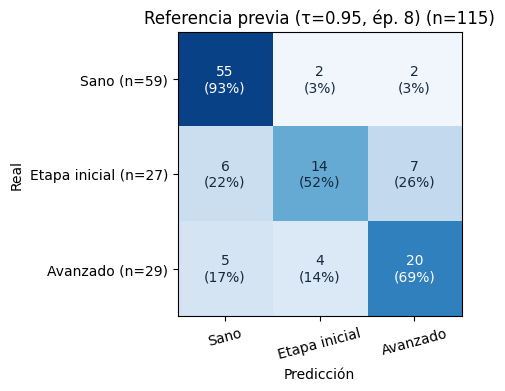

In [2]:
MATRIZ_REF = np.array([[55, 2, 2], [6, 14, 7], [5, 4, 20]])
y_ref, pred_ref = np.repeat(np.indices((3, 3)).reshape(2, -1), MATRIZ_REF.ravel(), axis=1)
metricas_ref, _ = u.calcular_metricas(y_ref, pred_ref, 3)
display(pd.DataFrame([metricas_ref], index=["Comprobacion_mejor_modelo.ipynb (n=115)"]).round(3))
u.graficar_matrices({"Referencia previa (τ=0.95, ép. 8)": MATRIZ_REF}, u.CLASES_3)

## 3. Entrenamiento trinario vs. binario y evaluación breve de estadios (`3→3`)

Ambos modelos usan exactamente la misma partición auditada de `Moondream` (`264 Sano / 115 Etapa inicial / 125 Avanzado`), semilla (`42`) y aumentos estándar (`RandomResizedCrop`, volteo horizontal, rotación $\pm 15^\circ$ y `ColorJitter`). La mejor época y los umbrales $\tau$ se fijan **solo en validación**.

Modelo cargado: convnext_tiny_3c_estandar.pth (mejor época 10)


Modelo 3 clases · ép. 10 · τ(Espec≥0.95)=0.81 (val=0.981) · τ(Youden)=0.81 (val=0.981)


Modelo cargado: convnext_tiny_2c_estandar.pth (mejor época 3)


Modelo 2 clases · ép. 3 · τ(Espec≥0.95)=0.90 (val=0.962) · τ(Youden)=0.86 (val=0.925)


,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,FN inicial,FN avanzado,errores sano ↔ avanzado
ConvNeXt 3 clases · Moondream test (auditado),95,0.731,0.789,0.935,0.898,0.102,0.065,0.476,0.84,0.801,3,0,3


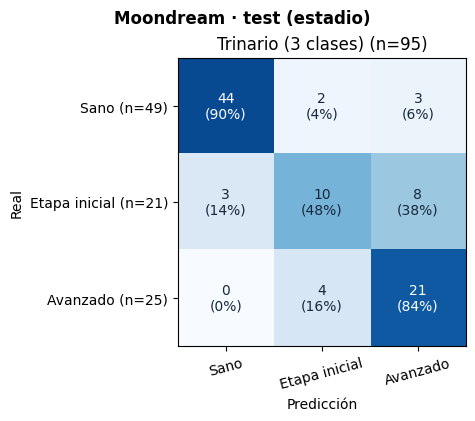

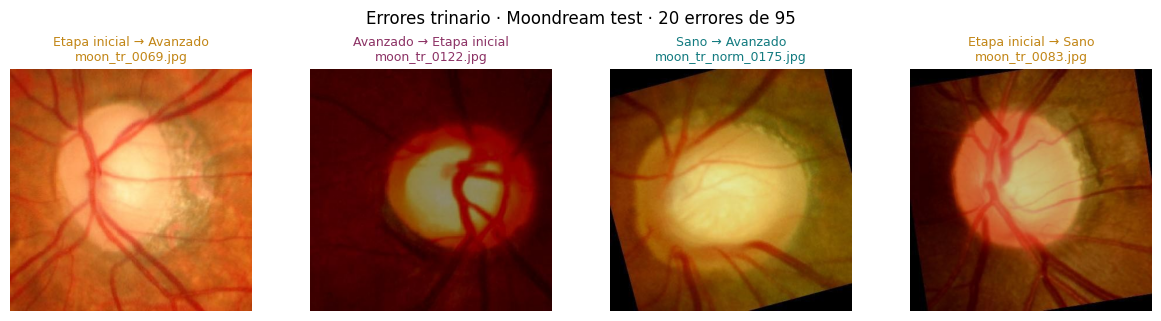

In [3]:
tf_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(u.MEAN, u.STD)])
tf_train = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03),
    T.ToTensor(),
    T.Normalize(u.MEAN, u.STD),
])

corridas = {}
for n_clases in (3, 2):
    ruta_pth = MODELOS / f"convnext_tiny_{n_clases}c_estandar.pth"
    res = u.entrenar_o_cargar(
        train_df, val_df, ROOT, n_clases, tf_train, tf_eval,
        ruta_modelo=ruta_pth, epochs=EPOCHS, batch_size=BATCH_SIZE,
        device=DEVICE, reentrenar=REENTRENAR, cache_imgs=cache_imgs,
    )
    y_val = val_df[f"y{n_clases}"].to_numpy(int)
    y_val_bin = val_df["y2"].to_numpy(int)
    tau, espec = u.calibrar_umbral(y_val, res["val_prob"], n_clases)
    tau_bin, espec_bin = (u.calibrar_umbral(y_val_bin, res["val_prob"], 2) if n_clases == 3 else (tau, espec))
    tau_youd, espec_youd = u.calibrar_youden(y_val_bin, res["val_prob"])

    probs = {}
    for nombre, df_eval in eval_sets.items():
        nivel = n_clases if nombre == "Moondream · test" else 2
        loader = u.crear_loader(df_eval, ROOT, nivel, tf_eval, batch_size=BATCH_SIZE, device=DEVICE, cache_imgs=cache_imgs)
        _, probs[nombre] = u.predecir(res["model"], loader, DEVICE, calcular_loss=False)

    corridas[n_clases] = {
        "epoca": res["epoca"], "tau": tau, "espec": espec,
        "tau_bin": tau_bin, "espec_bin": espec_bin,
        "tau_youd": tau_youd, "espec_youd": espec_youd, "probs": probs,
    }
    print(f"Modelo {n_clases} clases · ép. {res['epoca']} · τ(Espec≥0.95)={tau_bin:.2f} (val={espec_bin:.3f}) · τ(Youden)={tau_youd:.2f} (val={espec_youd:.3f})")
    del res["model"]
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# Evaluación breve de estadio (3 clases) en Moondream test
df_test_moon = eval_sets["Moondream · test"]
y3_test = df_test_moon["y3"].to_numpy(int)
pred3_test = u.decidir_con_umbral(corridas[3]["probs"]["Moondream · test"], corridas[3]["tau"])
met3, cm3 = u.calcular_metricas(y3_test, pred3_test, 3)
display(pd.DataFrame([met3], index=["ConvNeXt 3 clases · Moondream test (auditado)"]).round(3))
u.graficar_matrices({"Trinario (3 clases)": cm3}, u.CLASES_3, "Moondream · test (estadio)")
u.mostrar_errores(df_test_moon, y3_test, pred3_test, u.CLASES_3, ROOT, "Errores trinario · Moondream test")

## 4. Detección binaria y sensibilidad al punto de corte (`3→2` vs. `2→2`)

Comparamos **Proyección trinario** ($P(\text{Inicial}) + P(\text{Avanzado})$) frente a **Entrenado binario** con su regla principal calibrada en validación (`Espec. val ≥ 0.95`), y verificamos si la conclusión se mantiene bajo **Youden (`val`)** y **corte estándar `τ = 0.50`**.

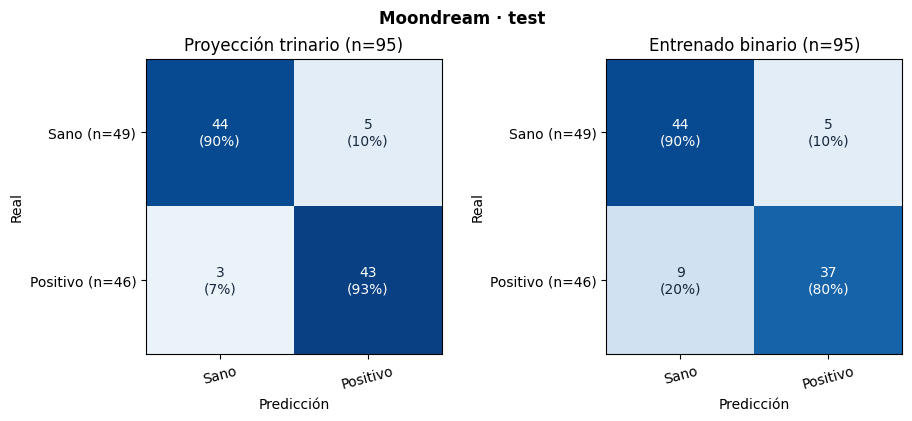

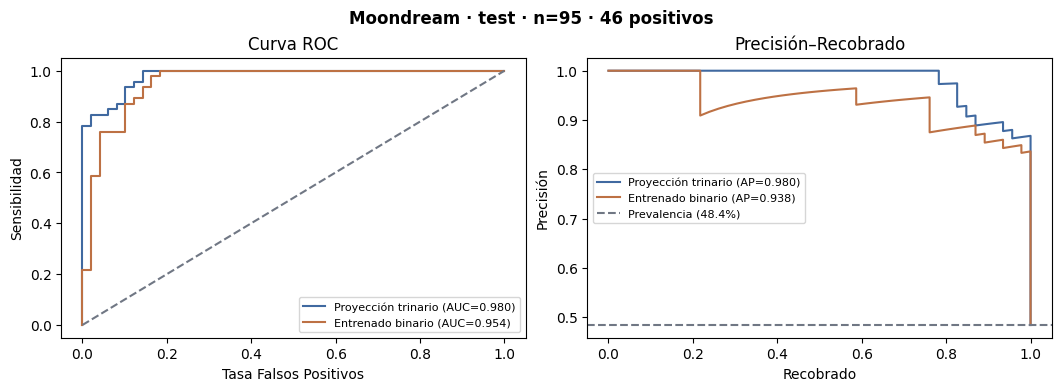

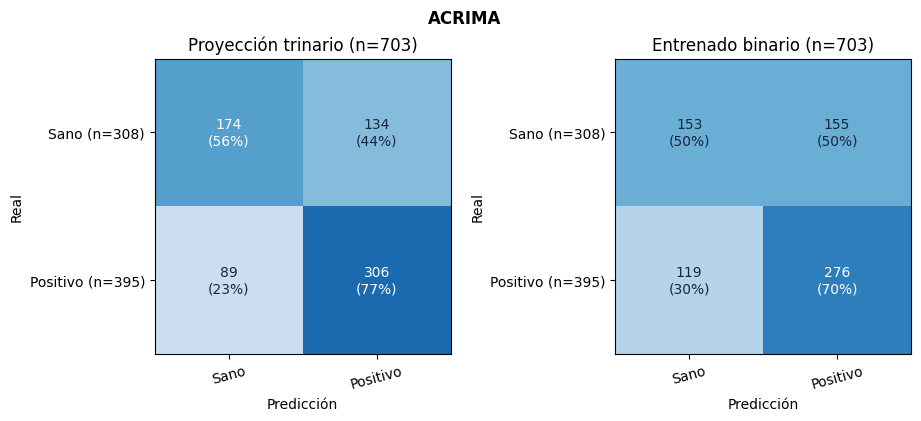

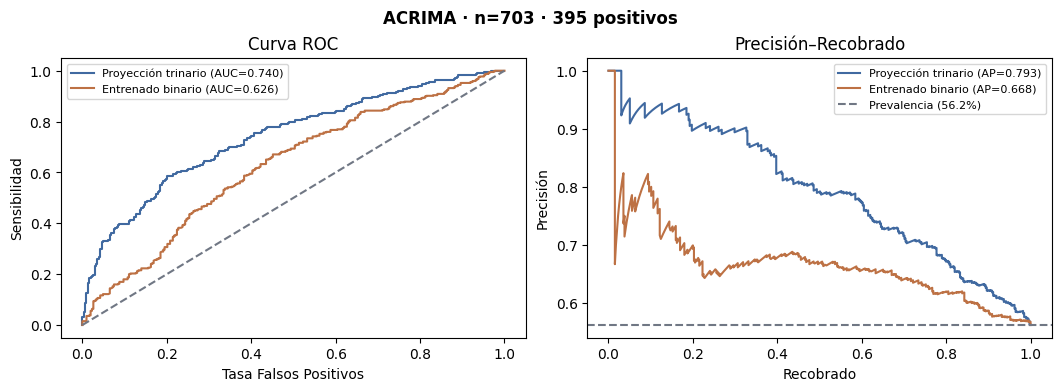

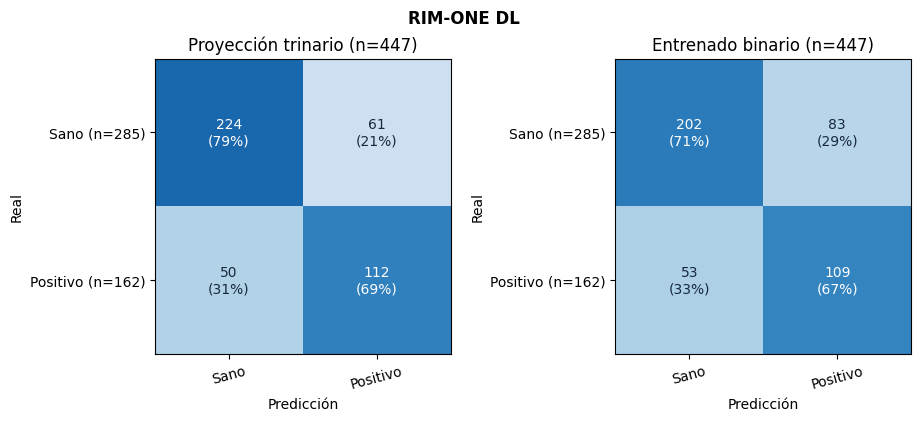

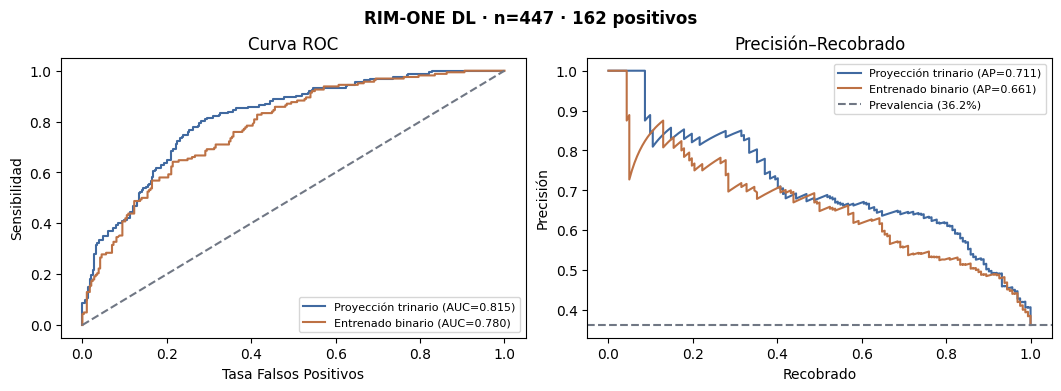

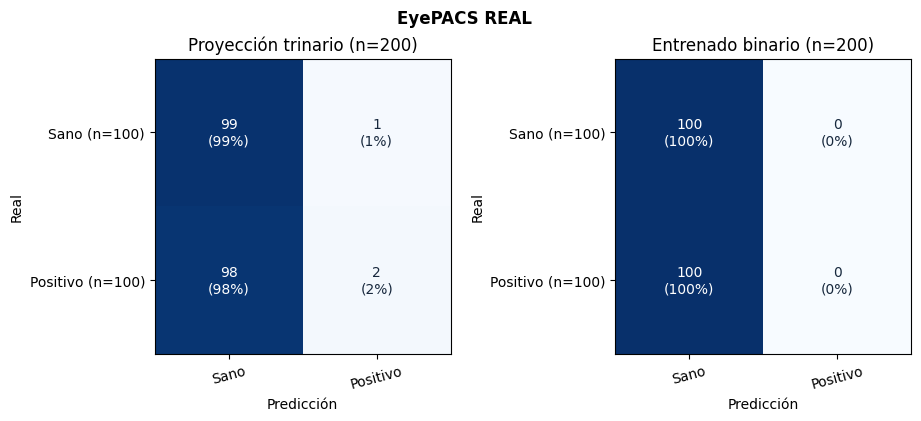

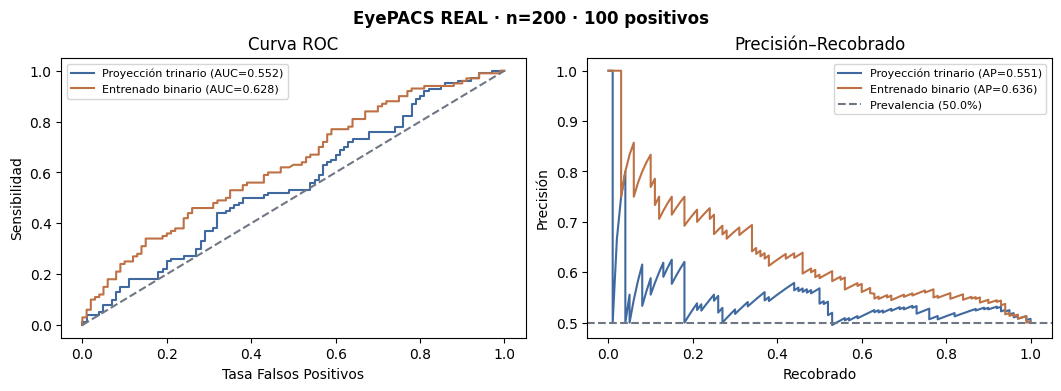

,cohorte,modelo,tau,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,FP,FN,AUROC,AP
0,Moondream · test,Proyección trinario,0.81,95,0.916,0.916,0.935,0.898,0.102,0.065,5,3,0.980,0.980
1,Moondream · test,Entrenado binario,0.90,95,0.852,0.853,0.804,0.898,0.102,0.196,5,9,0.954,0.938
2,ACRIMA,Proyección trinario,0.81,703,0.671,0.683,0.775,0.565,0.435,0.225,134,89,0.740,0.793
3,ACRIMA,Entrenado binario,0.90,703,0.598,0.610,0.699,0.497,0.503,0.301,155,119,0.626,0.668
4,RIM-ONE DL,Proyección trinario,0.81,447,0.735,0.752,0.691,0.786,0.214,0.309,61,50,0.815,0.711
5,RIM-ONE DL,Entrenado binario,0.90,447,0.682,0.696,0.673,0.709,0.291,0.327,83,53,0.780,0.661
6,EyePACS REAL,Proyección trinario,0.81,200,0.353,0.505,0.020,0.990,0.010,0.980,1,98,0.552,0.551
7,EyePACS REAL,Entrenado binario,0.90,200,0.333,0.500,0.000,1.000,0.000,1.000,0,100,0.628,0.636


Sensibilidad al punto de corte (F1 macro / Sensibilidad / Especificidad):


F1 macro                      \
modelo                               Entrenado binario Proyección trinario   
cohorte          regla                                                       
ACRIMA           Espec. val ≥ 0.95               0.598               0.671   
                 Estándar (τ = 0.50)             0.452               0.609   
                 Youden (val)                    0.589               0.671   
EyePACS REAL     Espec. val ≥ 0.95               0.333               0.353   
                 Estándar (τ = 0.50)             0.464               0.405   
                 Youden (val)                    0.333               0.353   
Moondream · test Espec. val ≥ 0.95               0.852               0.916   
                 Estándar (τ = 0.50)             0.862               0.905   
                 Youden (val)                    0.874               0.916   
RIM-ONE DL       Espec. val ≥ 0.95               0.682               0.735   
                 Estándar (τ = 0.50)             0.529               0.717   
                 Youden (val)                    0.669               0.735   

                                         especificidad                      \
modelo                               Entrenado binario Proyección trinario   
cohorte          regla                                                       
ACRIMA           Espec. val ≥ 0.95               0.497               0.565   
                 Estándar (τ = 0.50)             0.114               0.393   
                 Youden (val)                    0.429               0.565   
EyePACS REAL     Espec. val ≥ 0.95               1.000               0.990   
                 Estándar (τ = 0.50)             0.950               0.930   
                 Youden (val)                    1.000               0.990   
Moondream · test Espec. val ≥ 0.95               0.898               0.898   
                 Estándar (τ = 0.50)             0.735               0.816   
                 Youden (val)                    0.857               0.898   
RIM-ONE DL       Espec. val ≥ 0.95               0.709               0.786   
                 Estándar (τ = 0.50)             0.298               0.653   
                 Youden (val)                    0.618               0.786   

                                          sensibilidad                      
modelo                               Entrenado binario Proyección trinario  
cohorte          regla                                                      
ACRIMA           Espec. val ≥ 0.95               0.699               0.775  
                 Estándar (τ = 0.50)             0.939               0.841  
                 Youden (val)                    0.754               0.775  
EyePACS REAL     Espec. val ≥ 0.95               0.000               0.020  
                 Estándar (τ = 0.50)             0.150               0.090  
                 Youden (val)                    0.000               0.020  
Moondream · test Espec. val ≥ 0.95               0.804               0.935  
                 Estándar (τ = 0.50)             1.000               1.000  
                 Youden (val)                    0.891               0.935  
RIM-ONE DL       Espec. val ≥ 0.95               0.673               0.691  
                 Estándar (τ = 0.50)             0.969               0.840  
                 Youden (val)                    0.772               0.691

Diferencia pareada (Entrenado binario − Proyección trinario) con IC 95% bootstrap (incluye AUROC):


,medida,delta,ic95_inf,ic95_sup,cohorte,n
0,F1 macro,-0.064,-0.141,0.010,Moondream · test,95
1,sensibilidad,-0.130,-0.240,-0.022,Moondream · test,95
2,especificidad,0.000,-0.102,0.102,Moondream · test,95
3,AUROC,-0.026,-0.063,0.002,Moondream · test,95
4,F1 macro,-0.073,-0.102,-0.043,ACRIMA,703
5,sensibilidad,-0.076,-0.114,-0.041,ACRIMA,703
6,especificidad,-0.068,-0.114,-0.026,ACRIMA,703
7,AUROC,-0.114,-0.141,-0.090,ACRIMA,703
8,F1 macro,-0.053,-0.093,-0.016,RIM-ONE DL,447
9,sensibilidad,-0.019,-0.086,0.049,RIM-ONE DL,447


Moondream · test (n=95) · Δ F1=-6.4 pp · Δ Sens=-13.0 pp · Δ AUROC=-2.6 pp
ACRIMA (n=703) · Δ F1=-7.3 pp · Δ Sens=-7.6 pp · Δ AUROC=-11.4 pp
RIM-ONE DL (n=447) · Δ F1=-5.3 pp · Δ Sens=-1.9 pp · Δ AUROC=-3.4 pp
EyePACS REAL (n=200) · Δ F1=-1.9 pp · Δ Sens=-2.0 pp · Δ AUROC=+7.6 pp


In [4]:
registros, intervalos, predicciones_out, sens_umbral = [], [], [], []

for fuente, df_eval in eval_sets.items():
    y2 = df_eval["y2"].to_numpy(int)
    scores, decisiones, panel = {}, {}, {}

    for n_clases, etiqueta in ((3, "Proyección trinario"), (2, "Entrenado binario")):
        prob = corridas[n_clases]["probs"][fuente]
        sc = u.p_positivo(prob)
        tau_cons = corridas[n_clases]["tau_bin"]
        pred = (sc >= tau_cons).astype(int)
        scores[etiqueta] = sc
        decisiones[etiqueta] = pred
        stats, cm = u.calcular_metricas(y2, pred, 2, score_binario=sc)
        registros.append({"cohorte": fuente, "modelo": etiqueta, "tau": tau_cons, **stats})
        panel[etiqueta] = cm
        predicciones_out.append(df_eval[["id", "clase", "grupo", "y2"]].assign(
            cohorte=fuente, modelo=etiqueta, pred=pred, prob=sc
        ))
        for regla, t_val in [
            ("Espec. val ≥ 0.95", tau_cons),
            ("Youden (val)", corridas[n_clases]["tau_youd"]),
            ("Estándar (τ = 0.50)", 0.50),
        ]:
            m_t, _ = u.calcular_metricas(y2, (sc >= t_val).astype(int), 2, score_binario=sc)
            sens_umbral.append({"cohorte": fuente, "modelo": etiqueta, "regla": regla, "tau": t_val, **m_t})

    u.graficar_matrices(panel, u.CLASES_2, fuente)
    u.graficar_curvas_binarias(y2, scores, fuente)

    ic = u.bootstrap_diferencia(
        y2, decisiones["Proyección trinario"], decisiones["Entrenado binario"], 2,
        score_antes=scores["Proyección trinario"], score_despues=scores["Entrenado binario"],
    )
    if len(ic):
        intervalos.append(ic.assign(cohorte=fuente, n=len(df_eval)))

resumen_bin = pd.DataFrame(registros)
resumen_sens = pd.DataFrame(sens_umbral)
resumen_bin.to_csv(SALIDAS / "01_metricas_binarias.csv", index=False)
resumen_sens.to_csv(SALIDAS / "01_sensibilidad_umbral.csv", index=False)
pd.concat(predicciones_out, ignore_index=True).to_csv(SALIDAS / "01_predicciones_binarias.csv", index=False)

display(resumen_bin.round(3))
print("Sensibilidad al punto de corte (F1 macro / Sensibilidad / Especificidad):")
display(resumen_sens.pivot_table(index=["cohorte", "regla"], columns="modelo", values=["F1 macro", "sensibilidad", "especificidad"]).round(3))

if intervalos:
    print("Diferencia pareada (Entrenado binario − Proyección trinario) con IC 95% bootstrap (incluye AUROC):")
    display(pd.concat(intervalos, ignore_index=True).round(3))

for fuente, grp in resumen_bin.groupby("cohorte", sort=False):
    p = grp.set_index("modelo")
    diff = p.loc["Entrenado binario", ["F1 macro", "sensibilidad", "especificidad", "AUROC"]] - \
           p.loc["Proyección trinario", ["F1 macro", "sensibilidad", "especificidad", "AUROC"]]
    print(f"{fuente} (n={int(p.iloc[0].n)}) · Δ F1={100*diff['F1 macro']:+.1f} pp · "
          f"Δ Sens={100*diff.sensibilidad:+.1f} pp · Δ AUROC={100*diff.AUROC:+.1f} pp")

## 5. Limitaciones del experimento

- **Origen único estadificado:** `Moondream Staged` es el único conjunto con estadios reales (`Sano`, `Etapa inicial`, `Avanzado`); `ACRIMA`, `RIM-ONE DL` y `EyePACS REAL` solo cuentan con etiquetas binarias, por lo que no permiten validar severidad ni rotar el origen de entrenamiento en un esquema trinario.
- **Desbalance de estadio en `train` (`2 : 1 : 1`):** `Moondream train` tiene `264` sanos, `115` iniciales y `125` avanzados con entropía cruzada sin ponderar, lo que influye en el menor recobrado de `Etapa inicial` frente a `Avanzado`.
- **Evaluación en una sola dirección (`Moondream → resto`) y semilla única (`42`):** la generalización bidireccional multi-semilla se estudia de forma independiente en el experimento `05`.